# Lab Report: ODE_Initial Value Problem

In [1]:
from google.colab import files

ModuleNotFoundError: No module named 'google.colab'

In [2]:
# Required packages
import numpy as np
import matplotlib.pyplot as plt

## Problem statement - Implementing the Leapfrog Method to solve an IVP

In [3]:

def leapfrog(x,v,h):
    x0=x
    v0=v
    a= -(Wp)**2*x
    v_new=v0 + h * a
    x_new=x0 + h * v_new

    return(x_new, v_new)

t=20 
h=0.1## Calculating for t=20
n=int(t/h)
p=[]
p.append(0.5)
q=[]
q.append(0)
x=0.5
vi=0
Wp=1
a= -(Wp)**2*x
v=vi - (0.5*h*a)

for i in range(0,n):
    s=leapfrog(x,v,h)
    p.append(s[0])
    q.append(s[1])
    x=s[0]
    v=s[1]



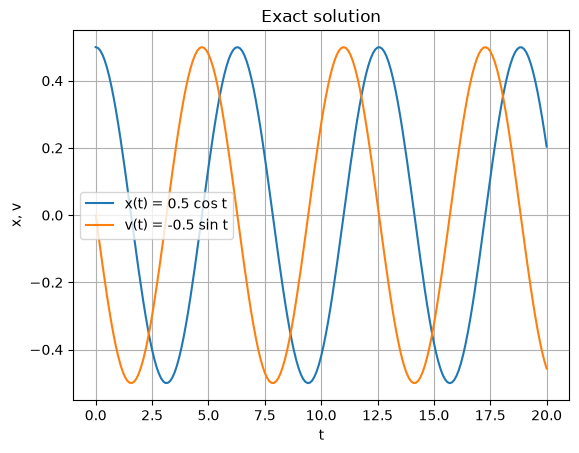

In [4]:
import numpy as np
import matplotlib.pyplot as plt

# time values from 0 to 20 
t=np.arange(0, 20.1, 0.1)

# exact solution
x_exact = 0.5 * np.cos(t)
v_exact = -0.5 * np.sin(t)

# plot position and velocity against time
plt.plot(t, x_exact, label="x(t) = 0.5 cos t")
plt.plot(t, v_exact, label="v(t) = -0.5 sin t")
plt.xlabel("t")
plt.ylabel("x, v")
plt.title("Exact solution")
plt.legend()
plt.grid(True)
plt.show()

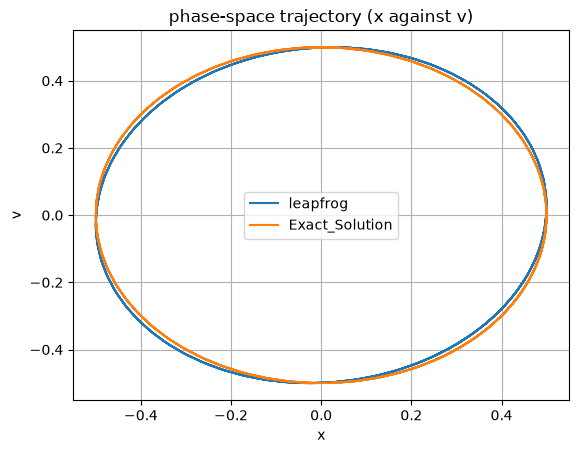

In [5]:
plt.plot(p,q,label="leapfrog")
plt.plot(x_exact,v_exact,label="Exact_Solution")
plt.xlabel("x")
plt.ylabel("v")
plt.title("phase-space trajectory (x against v)")
plt.legend()
plt.grid()
plt.show()

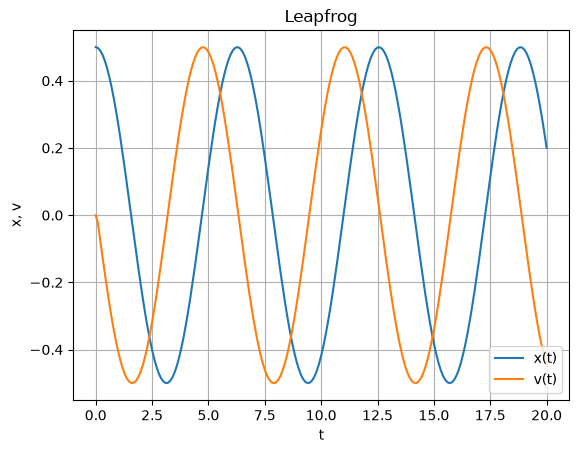

In [6]:
plt.plot(t,p,label="x(t)")
plt.plot(t,q,label="v(t)")
plt.title("Leapfrog")
plt.xlabel("t")
plt.ylabel("x, v")
plt.grid()
plt.legend()
plt.show()


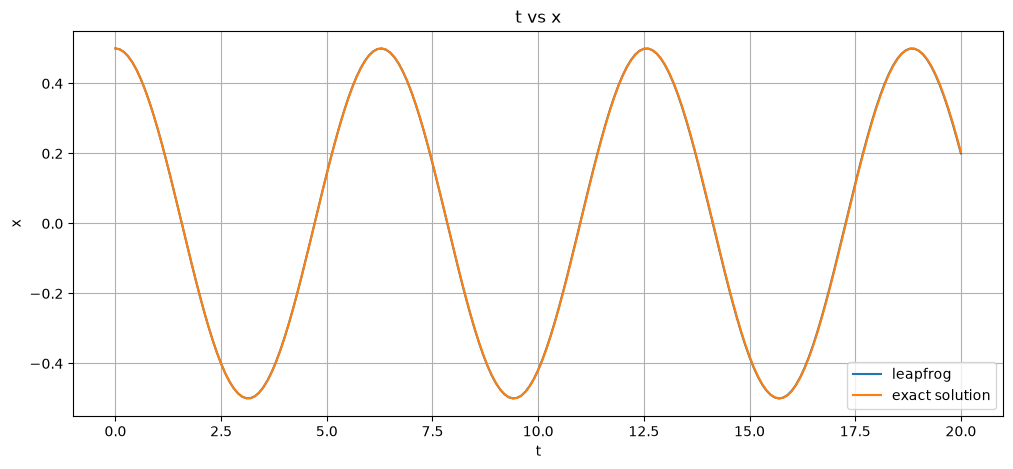

In [7]:
plt.figure(figsize=(12,5))
plt.plot(t,p,label="leapfrog")
plt.plot(t,x_exact,label="exact solution")
plt.title("t vs x")
plt.xlabel("t")
plt.ylabel("x")
plt.legend()
plt.grid()
plt.show()

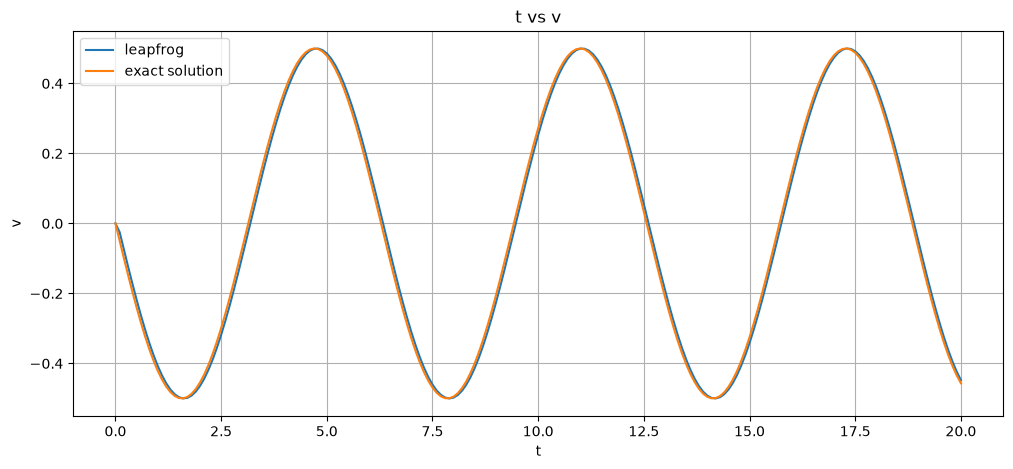

In [8]:
plt.figure(figsize=(12,5))
plt.plot(t,q,label="leapfrog")
plt.plot(t,v_exact,label="exact solution")
plt.title("t vs v")
plt.xlabel("t")
plt.ylabel("v")
plt.legend()
plt.grid()
plt.show()

In [9]:
h=np.array([0.2,0.16,0.125,0.1,0.08,0.05,0.04,0.025,0.02,])
w=len(h)
error_x=[]
error_v=[]
error_rms_x=[]
error_rms_v=[]
for i in range (0 , w):
    t=20
    h_new=h[i]
    n=int(t/h_new)
    x=0.5
    vi=0
    Wp=1
    a= -(Wp)**2*x
    v=vi - (0.5*h_new*a)
    p_new=[]
    q_new=[]
    p_new.append(x)
    q_new.append(vi)

    t=np.arange(0, 20+h_new, h_new)
    x_exact = 0.5 * np.cos(t)
    v_exact = -0.5 * np.sin(t)

    

    for j in range (0,n):
        s_new=leapfrog(x,v,h_new)
        p_new.append(s_new[0])
        q_new.append(s_new[1])
        x=s_new[0]
        v=s_new[1]

    x_diff= x_exact-p_new
    v_diff= v_exact-q_new
    
    max_error_x=np.max(abs(x_diff))         
    #print(f"max_error_x={max_error_x}")
    rms_error_x=np.sqrt(np.mean(x_diff**2))
    
    max_error_v=np.max(abs(v_diff))         
    #print(f"max_error_v={max_error_v}")
    rms_error_v=np.sqrt(np.mean(v_diff**2))
    
    
    error_x.append(max_error_x)
    error_v.append(max_error_v)
    error_rms_x.append(rms_error_x)
    error_rms_v.append(rms_error_v)


print(error_x)
print(error_v)
print(error_rms_x)
print(error_rms_v)

        
        

[np.float64(0.015396153502616333), np.float64(0.009812188342105094), np.float64(0.005971314855901938), np.float64(0.0038152808690173623), np.float64(0.0024391697225452924), np.float64(0.0009516945580628489), np.float64(0.0006089210013338342), np.float64(0.00023779054510253417), np.float64(0.00015217572309941807)]
[np.float64(0.049334665397530605), np.float64(0.03965910330712299), np.float64(0.031087366692613846), np.float64(0.024916708323414076), np.float64(0.019957346984586347), np.float64(0.012489584635339165), np.float64(0.00999466709331708), np.float64(0.006248697957356166), np.float64(0.00499933334666654)]
[np.float64(0.0067142722248951904), np.float64(0.00428092065239932), np.float64(0.0026052786157839633), np.float64(0.001664294180146946), np.float64(0.0010637147526956169), np.float64(0.00041476707590734776), np.float64(0.00026530744855645007), np.float64(0.00010355736953212025), np.float64(6.626097173252907e-05)]
[np.float64(0.029589491293155537), np.float64(0.02461875161400738

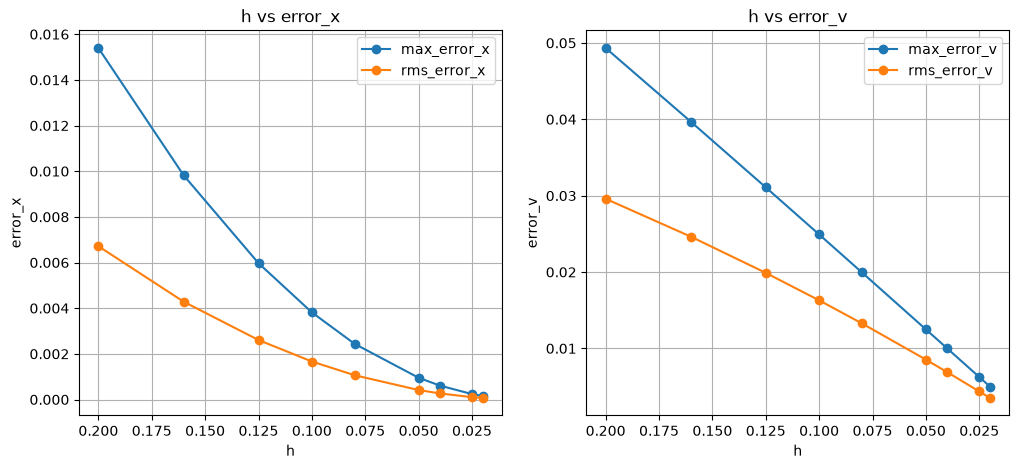

In [10]:
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.plot(h,error_x,'-o',label="max_error_x")
plt.plot(h,error_rms_x,'-o', label="rms_error_x")
plt.gca().invert_xaxis()
plt.title("h vs error_x")
plt.xlabel("h")
plt.ylabel("error_x")
plt.legend()
plt.grid()

plt.subplot(1,2,2)
plt.plot(h,error_v,'-o',label="max_error_v")
plt.plot(h,error_rms_v,'-o', label="rms_error_v")
plt.gca().invert_xaxis()
plt.title("h vs error_v")
plt.xlabel("h")
plt.ylabel("error_v")
plt.legend()
plt.grid()
plt.show()

### 5. Order of the method: elimination of $v$

**Leapfrog**

$$v_{n+\frac12} = v_{n-\frac12} + h\,a(x_n), \qquad a(x_n) = -\omega_p^2\,x_n \tag{1}$$

$$x_{n+1} = x_n + h\,v_{n+\frac12} \tag{2}$$

**Step 1: write for two consecutive steps**

From (2) at step $n$:

$$x_{n+1} - x_n = h\,v_{n+\frac12} \tag{3}$$

From (2) with $n \to n-1$:

$$x_n - x_{n-1} = h\,v_{n-\frac12} \tag{4}$$

**Step 2: subtract (4) from (3)**

$$x_{n+1} - 2x_n + x_{n-1} = h\left(v_{n+\frac12} - v_{n-\frac12}\right) \tag{5}$$

**Step 3: use the kick step to eliminate $v$**

From (1):

$$v_{n+\frac12} - v_{n-\frac12} = h\,a(x_n) = -\omega_p^2\,h\,x_n$$

Substituting into (5):

$$\boxed{x_{n+1} - 2x_n + x_{n-1} = -\,\omega_p^2\,h^2\,x_n}$$

This is the central difference formula for $\dfrac{d^2x}{dt^2} = -\omega_p^2 x$.

